In [1]:
import pandas as pd

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
df = pd.read_csv(url)
print(df.head())

   model_year  origin fuel_type         drivetrain  num_doors  \
0        2006  Europe  Gasoline  Front-wheel drive          4   
1        2008  Europe    Diesel  Front-wheel drive          4   
2        1996    Asia  Gasoline  Front-wheel drive          5   
3        1989  Europe  Gasoline  Front-wheel drive          4   
4        1994     USA    Diesel  Front-wheel drive          3   

   engine_displacement  num_cylinders  horsepower  vehicle_weight  \
0                 2180              6       243.0            3870   
1                 2390              6       272.0            4210   
2                 2320              6       267.0            4240   
3                 2130              6       258.0            4490   
4                 2580              7       304.0            4510   

   acceleration  fuel_efficiency_mpg  
0           NaN                 31.9  
1           NaN                 31.3  
2          17.3                 27.5  
3          18.7                 28.5  

In [2]:
df.columns=df.columns.str.lower()
df.head(
)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [3]:
df.describe()
df = df.fillna(0)
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,0.0,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,0.0,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
from sklearn.model_selection import train_test_split
df_full_train,df_test=train_test_split(df,test_size=0.2,random_state=1)
df_train,df_val=train_test_split(df_full_train,test_size=0.25,random_state=1)




In [5]:
df_train.reset_index(drop=True)
df_val.reset_index(drop=True)
df_test.reset_index(drop=True)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,1978,Asia,Gasoline,All-wheel drive,3,2230,6,247.0,4020,18.5,30.2
1,1986,Europe,Hybrid,Front-wheel drive,4,2120,6,235.0,4100,18.9,31.4
2,1996,USA,Diesel,Rear-wheel drive,4,2130,6,244.0,4410,19.8,28.6
3,1997,Europe,Gasoline,Front-wheel drive,2,1900,5,209.0,3590,19.0,32.6
4,1992,Europe,Gasoline,Rear-wheel drive,4,2210,6,229.0,4270,18.5,33.5
...,...,...,...,...,...,...,...,...,...,...,...
1995,1990,USA,Gasoline,Front-wheel drive,2,2210,6,202.0,4200,18.4,26.4
1996,1993,USA,Gasoline,All-wheel drive,4,2160,6,248.0,4680,20.2,26.0
1997,2015,Asia,Gasoline,Rear-wheel drive,4,2420,7,260.0,4820,17.7,32.5
1998,2016,USA,Gasoline,Front-wheel drive,2,2050,6,246.0,4250,18.6,31.8


In [6]:
y_train=df_train["fuel_efficiency_mpg"].values
y_val=df_val["fuel_efficiency_mpg"].values
y_test=df_test["fuel_efficiency_mpg"].values

In [7]:
print("Mean:", y_train.mean())
print("Min:", y_train.min())
print("Max:", y_train.max())

Mean: 30.01151666666667
Min: 19.8
Max: 41.2


In [8]:
del df_train["fuel_efficiency_mpg"]
del df_val["fuel_efficiency_mpg"]
del df_test["fuel_efficiency_mpg"]

In [33]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.feature_extraction import DictVectorizer
train_dicts=df_train.to_dict(orient='records')
dv=DictVectorizer(sparse=False)
X_train=dv.fit_transform(train_dicts)


In [34]:
dt=DecisionTreeRegressor(max_depth=1,random_state=1)
dt.fit(X_train,y_train)
y_pred=dt.predict(X_train)
from sklearn.metrics import mean_squared_error
import numpy as np
rmse=np.sqrt(mean_squared_error(y_train,y_pred))
rmse

np.float64(2.6405603669897904)

In [11]:
val_dicts=df_val.to_dict(orient='records')
X_val=dv.transform(val_dicts)


In [12]:
y_pred=dt.predict(X_val)
y_pred

array([28.61358616, 28.61358616, 28.61358616, ..., 31.16766139,
       28.61358616, 28.61358616], shape=(2000,))

In [13]:
from sklearn.metrics import mean_squared_error
import numpy as np


rmse=np.sqrt(mean_squared_error(y_val,y_pred))
rmse

np.float64(2.672633736937051)

Question 1    (model_year)

In [14]:
from sklearn.tree import export_text
print(export_text(dt,feature_names=dv.get_feature_names_out()))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



In [15]:
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor(n_estimators=10,random_state=1,n_jobs=-1)
rf.fit(X_train,y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

In [16]:
y_pred=rf.predict(X_val)

Question 2  (1.839)


In [17]:
rmse=np.sqrt(mean_squared_error(y_val,y_pred))
rmse


np.float64(1.8392210851335953)

In [18]:
scores=[]
for n in [10,50,100,150]:
    rf=RandomForestRegressor(n_estimators=n,random_state=1,n_jobs=-1)
    rf.fit(X_train,y_train)

    y_pred=rf.predict(X_val)
    rmse=np.sqrt(mean_squared_error(y_val,y_pred))
    scores.append((n,rmse))
    

Question 3  (100)

In [19]:
scores

[(10, np.float64(1.8392210851335953)),
 (50, np.float64(1.772874533631751)),
 (100, np.float64(1.7681584001440593)),
 (150, np.float64(1.7676924977055388))]

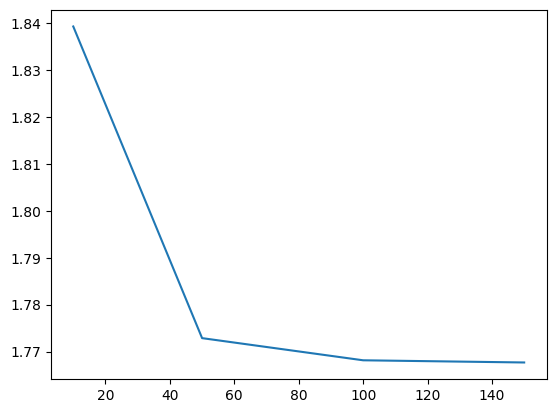

In [20]:
df_scores=pd.DataFrame(scores,columns=['n_estimators','rmse'])
import matplotlib.pyplot as plt
plt.plot(df_scores['n_estimators'],df_scores['rmse'])



In [21]:
scores=[]
for d in [10,15,20,25]:
    for n in [10,50,100,150]:
        rf=RandomForestRegressor(n_estimators=n,max_depth=d,random_state=1,n_jobs=-1)
        rf.fit(X_train,y_train)

        y_pred=rf.predict(X_val)
        rmse=np.sqrt(mean_squared_error(y_val,y_pred))
        scores.append((d,n,rmse))
    

In [22]:
scores

[(10, 10, np.float64(1.786430132915972)),
 (10, 50, np.float64(1.748301774052068)),
 (10, 100, np.float64(1.745137200048692)),
 (10, 150, np.float64(1.7440084795286572)),
 (15, 10, np.float64(1.8366755256533889)),
 (15, 50, np.float64(1.7723852774875055)),
 (15, 100, np.float64(1.7692046157854968)),
 (15, 150, np.float64(1.7677735969597408)),
 (20, 10, np.float64(1.841211429196157)),
 (20, 50, np.float64(1.7725555954972803)),
 (20, 100, np.float64(1.7680047119419044)),
 (20, 150, np.float64(1.767195723402056)),
 (25, 10, np.float64(1.839476204804396)),
 (25, 50, np.float64(1.7744110942078373)),
 (25, 100, np.float64(1.7694877056203273)),
 (25, 150, np.float64(1.7688530451625237))]

In [23]:
df_scores=pd.DataFrame(scores,columns=['max_depth','n_estimators','rmse'])
df_scores


,max_depth,n_estimators,rmse
0,10,10,1.786430
1,10,50,1.748302
2,10,100,1.745137
3,10,150,1.744008
4,15,10,1.836676
5,15,50,1.772385
6,15,100,1.769205
7,15,150,1.767774
8,20,10,1.841211
9,20,50,1.772556


Question 4  (10)

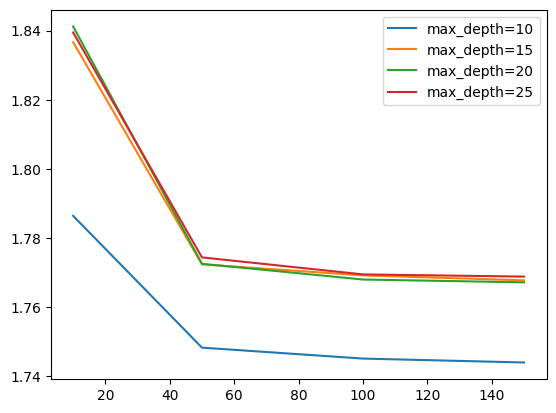

In [24]:
for d in [10,15,20,25]:
    df_subset=df_scores[df_scores.max_depth==d]
    plt.plot(df_subset['n_estimators'],df_subset['rmse'],label='max_depth=%d' %d)
    plt.legend()

Question 5 (vehicle_weight)

In [26]:
rf=RandomForestRegressor(n_estimators=10,max_depth=20,random_state=1,n_jobs=-1)
rf.fit(X_train,y_train)
importance_df=pd.DataFrame({'feature':dv.get_feature_names_out(),'importance':rf.feature_importances_})
importance_df.sort_values('importance',ascending=False).head(10)



,feature,importance
9,model_year,0.295917
15,vehicle_weight,0.203420
6,fuel_type=Gasoline,0.160713
8,horsepower,0.077732
4,engine_displacement,0.061682
0,acceleration,0.055387
14,origin=USA,0.042299
2,drivetrain=Front-wheel drive,0.020116
5,fuel_type=Diesel,0.020037
11,num_doors,0.019322


In [30]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [36]:
import xgboost as xgb
features=list(dv.get_feature_names_out())
dtrain=xgb.DMatrix(X_train,label=y_train,feature_names=features)
dval=xgb.DMatrix(X_val,label=y_val,feature_names=features)


In [47]:
xgb_params={
    'eta':0.3,'max_depth':6,'min_child_weight':1,'objective':'reg:squarederror','nthread':8,'seed':1,'verbosity':1
}
model=xgb.train(xgb_params,dtrain,num_boost_round=100)

In [48]:
y_pred=model.predict(dval)

Question 6   (0.1)

In [49]:
rmse=np.sqrt(mean_squared_error(y_val,y_pred))
rmse

np.float64(1.8264579799904583)